In [31]:
# Import all the neccessary packages
import numpy as np
import clip
import os
from PIL import Image
import matplotlib.pyplot as plt
import torch
import copy
from IPython.display import display
from sklearn.cluster import KMeans
import time

Total # of images: 20
The 3 themes are bottle, book, and dishes


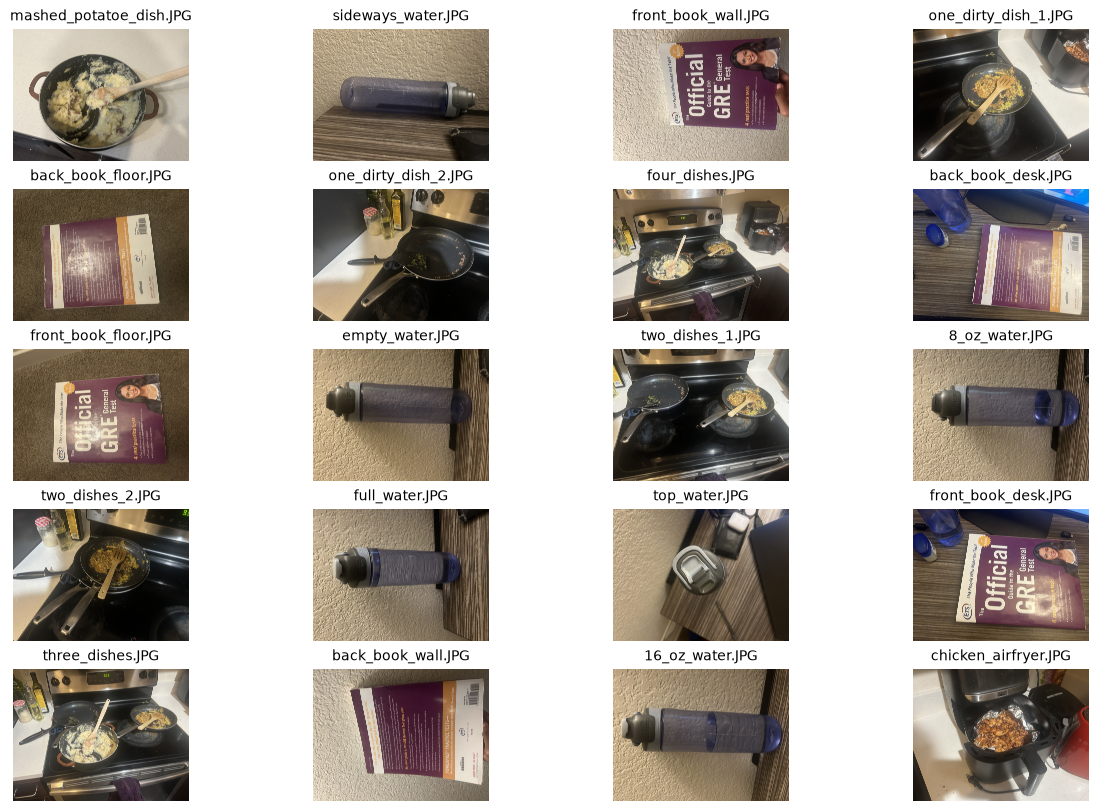

In [32]:
# Create thumbnail image of all 20 images
device = "cpu"
img_dir = "img/"
img_paths = os.listdir(img_dir)
images = []
print(f"Total # of images: {len(img_paths)}")
print("The 3 themes are bottle, book, and dishes")
for img in img_paths:
    images.append((Image.open(img_dir+img).convert("RGB")))
cols = 4
n_images = len(images)
rows = (n_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()

for i in range(len(axes)):
    if i < n_images:
        axes[i].imshow(images[i])
        axes[i].set_title(img_paths[i], fontsize=10)
        axes[i].axis('off')
    else:
        axes[i].axis('off')
        
plt.show()


In [33]:
# preprocess and embed the images
model, preprocess = clip.load("ViT-B/32")
model.eval()
img_tensor = []
for img in images:
    img_tensor.append(preprocess(img))

image_batch = torch.stack(img_tensor).to(device)
t =  time.time_ns()
with torch.inference_mode():
    raw_image_embeddings = model.encode_image(image_batch).float()
print(raw_image_embeddings.shape)
image_embeddings = raw_image_embeddings / raw_image_embeddings.norm(dim=1, keepdim=True)
print(f"embedding time is {time.time_ns() - t}")


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


torch.Size([20, 512])
embedding time is 345543000


In [34]:
# norm calculations needed pre and post normalization for report
print(f"{img_paths[0]} norm: {image_embeddings[0].norm()}, {img_paths[1]} norm: {image_embeddings[1].norm()}, {img_paths[2]} norm: {image_embeddings[2].norm()}")
print(f"{img_paths[0]} norm: {raw_image_embeddings[0].norm()}, {img_paths[1]} norm: {raw_image_embeddings[1].norm()}, {img_paths[2]} norm: {raw_image_embeddings[2].norm()}")


mashed_potatoe_dish.JPG norm: 0.9999998807907104, sideways_water.JPG norm: 1.000000238418579, front_book_wall.JPG norm: 1.0
mashed_potatoe_dish.JPG norm: 10.455253601074219, sideways_water.JPG norm: 11.269920349121094, front_book_wall.JPG norm: 9.206995964050293


Similarity score: [0.26053873]


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/2558944579.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image, text_embedding.T))


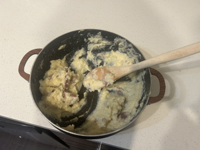

Similarity score: [0.25108385]


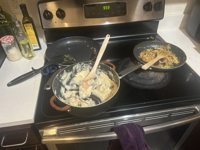

Similarity score: [0.24289557]


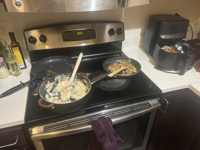

In [96]:
# semantic search function implementation
def search(query: str, k=3):
    tokens = clip.tokenize([query]).to(device)
    with torch.inference_mode():
        text_embedding = model.encode_text(tokens).float()
    text_embedding = text_embedding / text_embedding.norm(dim=1, keepdim=True)
    similarity = []
    
    for image in image_embeddings:
        similarity.append(np.dot(image, text_embedding.T))

    temp_img_paths = copy.deepcopy(img_paths)
    similarity, temp_img_paths = map(list, zip(*sorted(zip(similarity, temp_img_paths), reverse=True)))
    for i in range(k):
        print(f"Similarity score: {similarity[i]}")
        img = Image.open(img_dir + temp_img_paths[i])
        img.thumbnail((200, 200))
        display(img)



0:


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/3618366748.py:27: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  temp_img_embeddings[i] - kmean.cluster_centers_[current_cluster]


Avg Euclidian Dist is: 0.4704298301317324

1:


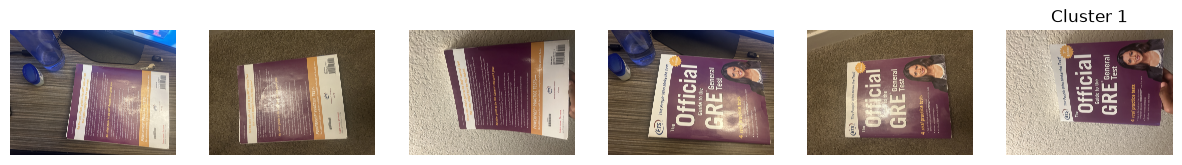

Avg Euclidian Dist is: 0.3286992235490071

2:


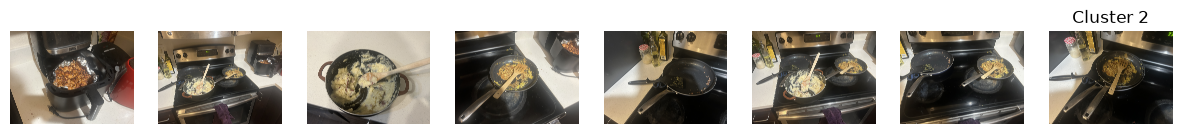

Avg Euclidian Dist is: 0.2932200322010618


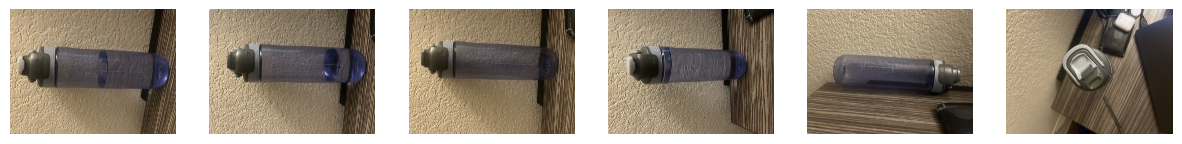

In [120]:
# Cluster the images, find euclidean distances for each cluster, and create diagram showing images in each cluster
kmean = KMeans(n_clusters=3, random_state=42)
clusters = kmean.fit_predict(image_embeddings)

temp_img_paths = copy.deepcopy(img_paths)
temp_img_embeddings = copy.deepcopy(image_embeddings)
clusters, temp_img_paths, temp_img_embeddings = map(list, zip(*sorted(zip(clusters, temp_img_paths, temp_img_embeddings))))
current_cluster = 0
distances = 0
count = 0
print(f"\n{current_cluster}:")
avg_distances_ls = []
fig, axes = plt.subplots(1, clusters.count(current_cluster), figsize=(15, 3))
for i in range(len(img_paths)):
    if current_cluster != clusters[i]:
        avg_distances_ls.append(distances/count)
        print(f"Avg Euclidian Dist is: {avg_distances_ls[-1]}")
        distances = 0
        count = 0
        current_cluster += 1
        print(f"\n{current_cluster}:")
        plt.title(f"Cluster {current_cluster}")
        plt.show()
        fig, axes = plt.subplots(1, clusters.count(current_cluster), figsize=(15, 3))

    
    distances += np.linalg.norm(
        temp_img_embeddings[i] - kmean.cluster_centers_[current_cluster]
    )
    
    axes[count].imshow(Image.open("img/"+temp_img_paths[i]))
    axes[count].axis("off")
    count += 1
    
avg_distances_ls.append(distances/count)
print(f"Avg Euclidian Dist is: {avg_distances_ls[-1]}")


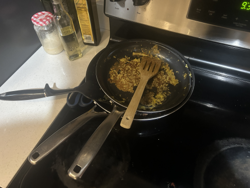

Similarity score: 0.960325300693512


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/3096088469.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image_embeddings[i], image_embeddings[index]))


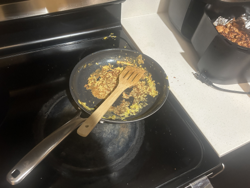

Similarity score: 0.937680721282959


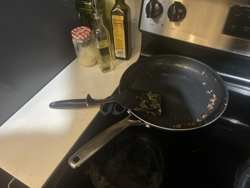

In [107]:
# image to image search implementation
def image_search(path: str, k=3):
    index = img_paths.index(path)
    similarity = []
    
    for i in range(len(image_embeddings)):
        if i == index:
            similarity.append(0)
            continue
        similarity.append(np.dot(image_embeddings[i], image_embeddings[index]))

    temp_img_paths = copy.deepcopy(img_paths)
    similarity, temp_img_paths = map(list, zip(*sorted(zip(similarity, temp_img_paths), reverse=True)))
    for i in range(k):
        print(f"Similarity score: {similarity[i]}")
        img = Image.open(img_dir + temp_img_paths[i])
        img.thumbnail((250, 250))
        display(img)

# image to image search example for report
img = Image.open(img_dir + "two_dishes_2.JPG")
img.thumbnail((250, 250))
display(img)
image_search("two_dishes_2.JPG", k=2)

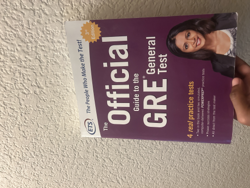

Similarity score: 0.8555967807769775


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/3108987165.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image_embeddings[i], image_embeddings[index]))


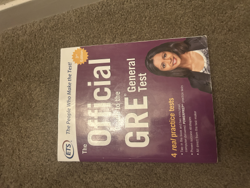

Similarity score: 0.7902880311012268


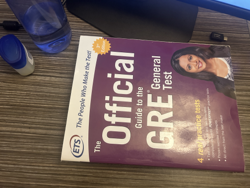

In [106]:
# second image to image search for report
img = Image.open(img_dir + "front_book_wall.JPG")
img.thumbnail((250, 250))
display(img)
image_search("front_book_wall.JPG", k=2)

Similarity score: 0.9603253602981567


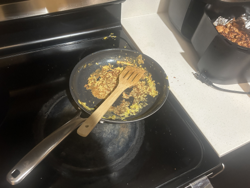

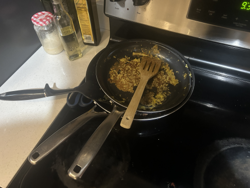

Similarity score: 0.9582345485687256


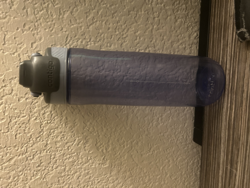

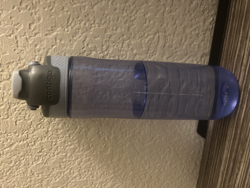

Similarity score: 0.9514404535293579


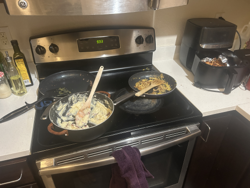

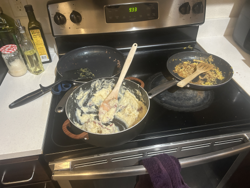

Similarity score: 0.9493831992149353


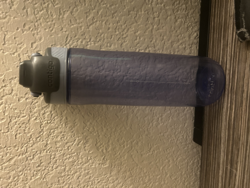

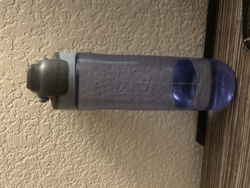

Similarity score: 0.9376809597015381


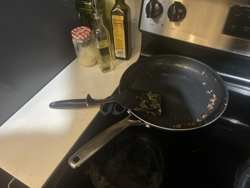

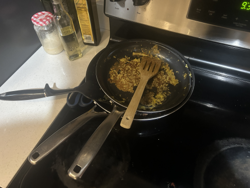

In [45]:
# find and display top 5 most similar pairs of images with similarity score 
mat = image_embeddings.numpy()
norms = np.linalg.norm(mat, axis=1, keepdims=True)
similarities = (mat@mat.T) / (norms@norms.T)
rows, cols = np.triu_indices(len(image_embeddings.numpy()), k=1)
scores = similarities[rows, cols]

top_indices = np.argsort(scores)[-5:][::-1]
top_5 = [
    (rows[k], cols[k], scores[k])
    for k in top_indices
]
for i in range(5):
    print(f"Similarity score: {top_5[i][2]}")
    img = Image.open(img_dir + img_paths[top_5[i][0]])
    img.thumbnail((250, 250))
    display(img)
    img = Image.open(img_dir + img_paths[top_5[i][1]])
    img.thumbnail((250, 250))
    display(img)


Similarity score: [0.26053873]


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/2558944579.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image, text_embedding.T))


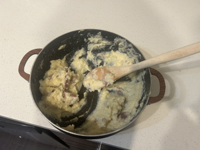

Similarity score: [0.25108385]


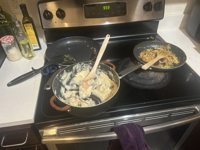

Similarity score: [0.24289557]


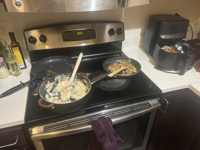

In [97]:
# Analysis section of report, works well example
search("Mashed potatoes")

Similarity score: [0.29507658]


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/2558944579.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image, text_embedding.T))


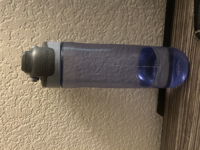

Similarity score: [0.29368243]


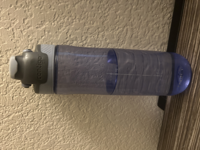

Similarity score: [0.28950745]


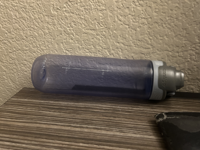

Similarity score: [0.2845293]


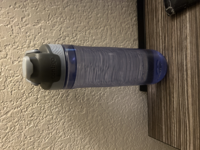

Similarity score: [0.28163573]


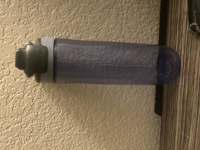

In [101]:
# Analysis section of report, fails to find empty water
search("empty water bottle", k=5)

Similarity score: [0.33450595]


/var/folders/1b/qlbscsf57hngyt99v1b1329c0000gn/T/ipykernel_59761/2558944579.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  similarity.append(np.dot(image, text_embedding.T))


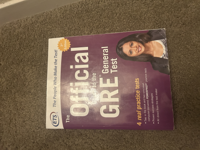

Similarity score: [0.33228332]


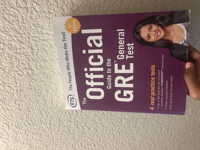

Similarity score: [0.28326935]


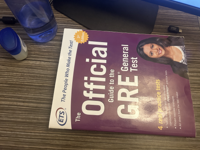

In [99]:
# Analysis section of report, reads the text on book
search("Official guide to the gre")